In [ ]:
CIND 820: Capstone Project:Saphora Product Review


In [ ]:
Preparation:
The dataset is related to Saphora.

Import the following files: http://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv
http://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
   

In [25]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

# Load dataset safely
saphora = pd.read_csv(
    r"C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora Products and Skincare Reviews_uncleaned.csv",
    low_memory=False
)
saphora.dtypes


Unnamed: 0                    int64
author_id                    object
rating                        int64
is_recommended              float64
helpfulness                 float64
total_feedback_count          int64
total_neg_feedback_count      int64
total_pos_feedback_count      int64
submission_time              object
review_text                  object
review_title                 object
skin_tone                    object
eye_color                    object
skin_type                    object
hair_color                   object
product_id                   object
product_name                 object
brand_name                   object
price_usd                   float64
dtype: object

In [37]:
saphora.head()

,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1945004256,5,1.0,0.000000,2,2,0,2022-12-10,I absolutely L-O-V-E this oil. I have acne pro...,A must have!,lightMedium,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
1,1,5478482359,3,1.0,0.333333,3,2,1,2021-12-17,I gave this 3 stars because it give me tiny li...,it keeps oily skin under control,mediumTan,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
2,2,29002209922,5,1.0,1.000000,2,0,2,2021-06-07,Works well as soon as I wash my face and pat d...,Worth the money!,lightMedium,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
3,3,7391078463,5,1.0,1.000000,2,0,2,2021-05-21,"this oil helped with hydration and breakouts, ...",best face oil,lightMedium,brown,combination,blonde,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
4,4,1766313888,5,1.0,1.000000,13,0,13,2021-03-29,This is my first product review ever so that s...,Maskne miracle,mediumTan,brown,combination,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0


In [39]:

null_counts = saphora.isnull().sum()
null_pct = (saphora.isnull().mean() * 100).round(2)
null_summary = pd.concat([null_counts.rename('null_count'), null_pct.rename('null_%')], axis=1)
display(null_summary.sort_values('null_count', ascending=False).head(20))

# Save summary
null_summary.to_csv('sephora_uncleaned_null_summary.csv')
print('✅ Null summary saved as sephora_uncleaned_null_summary.csv')

,null_count,null_%
review_title,14378,28.77
helpfulness,13455,26.92
hair_color,8851,17.71
skin_tone,7201,14.41
eye_color,6260,12.53
is_recommended,3817,7.64
skin_type,3631,7.27
review_text,59,0.12
brand_name,0,0.00
product_name,0,0.00


✅ Null summary saved as sephora_uncleaned_null_summary.csv


In [47]:

# -----------------------------
# 1️⃣ Load and normalize schema
# -----------------------------

RAW_PATH = r"C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora Products and Skincare Reviews_uncleaned.csv"

# Read CSV safely
saphora = pd.read_csv(RAW_PATH, low_memory=False)

# Normalize column names: lowercase, remove spaces
saphora.columns = [c.strip().lower().replace(" ", "_") for c in saphora.columns]

# Helper to pick first available column
def first_existing(_df, candidates):
    for c in candidates:
        if c in _df.columns:
            return c
    return None

# Identify key columns dynamically
col_rating    = first_existing(saphora, ["rating", "stars", "star_rating"])
col_review    = first_existing(saphora, ["review_text", "review", "text", "content"])
col_title     = first_existing(saphora, ["review_title", "title", "summary"])
col_price     = first_existing(saphora, ["price"])
col_brand     = first_existing(saphora, ["brand"])
col_product   = first_existing(saphora, ["product_name", "product", "item_name"])
col_skin_type = first_existing(saphora, ["skin_type"])
col_skin_tone = first_existing(saphora, ["skin_tone"])
col_helpful   = first_existing(saphora, ["helpfulness", "helpful_votes", "feedback"])

print("✅ Columns mapped:")
print(" rating   ->", col_rating)
print(" review   ->", col_review)
print(" title    ->", col_title)
print(" price    ->", col_price)
print(" brand    ->", col_brand)
print(" product  ->", col_product)
print(" skin_type->", col_skin_type)
print(" skin_tone->", col_skin_tone)
print(" helpful  ->", col_helpful)
print("Rows x Cols:", saphora.shape)
saphora.head(3)


✅ Columns mapped:
 rating   -> rating
 review   -> review_text
 title    -> review_title
 price    -> None
 brand    -> None
 product  -> product_name
 skin_type-> skin_type
 skin_tone-> skin_tone
 helpful  -> helpfulness
Rows x Cols: (49977, 19)


,unnamed:_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1945004256,5,1.0,0.000000,2,2,0,2022-12-10,I absolutely L-O-V-E this oil. I have acne pro...,A must have!,lightMedium,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
1,1,5478482359,3,1.0,0.333333,3,2,1,2021-12-17,I gave this 3 stars because it give me tiny li...,it keeps oily skin under control,mediumTan,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0
2,2,29002209922,5,1.0,1.000000,2,0,2,2021-06-07,Works well as soon as I wash my face and pat d...,Worth the money!,lightMedium,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0


In [51]:
# ==========================================================
# 3️⃣ Data Cleaning for Sephora Dataset
# ==========================================================

# --- Convert rating to numeric and filter valid range (1–5)
if col_rating:
    saphora[col_rating] = pd.to_numeric(saphora[col_rating], errors="coerce")
    saphora = saphora[(saphora[col_rating] >= 1) & (saphora[col_rating] <= 5)]

# --- Convert price to numeric (if it exists)
if col_price:
    saphora[col_price] = pd.to_numeric(saphora[col_price], errors="coerce")

# --- Clean text columns: strip whitespace and cast to string
for c in [col_review, col_title, col_brand, col_product, col_skin_type, col_skin_tone]:
    if c and c in saphora.columns:
        saphora[c] = saphora[c].astype(str).str.strip()

# --- Remove duplicate rows using key columns
dup_keys = [c for c in [col_product, col_brand, col_title, col_review, col_rating] if c and c in saphora.columns]
if dup_keys:
    before = len(saphora)
    saphora = saphora.drop_duplicates(subset=dup_keys)
    after = len(saphora)
    print(f"✅ Removed duplicates: {before - after}")

print("✅ After cleaning:", saphora.shape)

✅ Removed duplicates: 0
✅ After cleaning: (49856, 19)


In [53]:
# ==========================================================
# 4️⃣ Feature Engineering – Create new derived columns
# ==========================================================

import numpy as np

# --- Create review length feature (number of words in review)
if col_review and col_review in saphora.columns:
    saphora["review_len"] = saphora[col_review].fillna("").str.split().apply(len)
else:
    saphora["review_len"] = np.nan

print("✅ Feature 'review_len' added successfully.")
saphora.head(3)

✅ Feature 'review_len' added successfully.


,unnamed:_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd,review_len
0,0,1945004256,5,1.0,0.000000,2,2,0,2022-12-10,I absolutely L-O-V-E this oil. I have acne pro...,A must have!,lightMedium,green,combination,NaN,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0,168
1,1,5478482359,3,1.0,0.333333,3,2,1,2021-12-17,I gave this 3 stars because it give me tiny li...,it keeps oily skin under control,mediumTan,brown,oily,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0,60
2,2,29002209922,5,1.0,1.000000,2,0,2,2021-06-07,Works well as soon as I wash my face and pat d...,Worth the money!,lightMedium,brown,dry,black,P379064,Lotus Balancing & Hydrating Natural Face Treat...,Clarins,65.0,16


In [73]:
# ==========================================================
# 5️⃣ Save Cleaned & Enriched Sephora Dataset
# ==========================================================

from pathlib import Path

# Define where to save the cleaned file
CLEAN_PATH = Path(r"C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\sephora_reviews_cleaned.csv\sephora_cleaned.csv")

# Save the cleaned and feature-engineered DataFrame
saphora.to_csv(CLEAN_PATH, index=False)

print("✅ [OK] Cleaned data saved to:", CLEAN_PATH)
print("📏 Shape:", saphora.shape)


✅ [OK] Cleaned data saved to: C:\Users\akaze\OneDrive\Desktop\Big Data\CIND 820\Capston\Sephora-BigData-Project\sephora_reviews_cleaned.csv\sephora_cleaned.csv
📏 Shape: (49856, 20)


In [57]:
# ==========================================================
# 6️⃣ Descriptive Tables & Aggregated Summaries
# ==========================================================

# Identify numeric columns of interest
numeric_cols = [c for c in [col_rating, col_price, "review_len"] if c in saphora.columns]

# --- Overall numeric summary
if numeric_cols:
    print("📊 Numeric Summary:")
    display(saphora[numeric_cols].describe().T)

# --- Brand-level summary (top 20 brands by review count)
if col_brand and col_rating and col_brand in saphora.columns and col_rating in saphora.columns:
    brand_summary = (
        saphora.groupby(col_brand)[col_rating]
        .agg(n_reviews="count", avg_rating="mean")
        .sort_values("n_reviews", ascending=False)
        .head(20)
        .reset_index()
    )
    print("\n🏷️ Top 20 Brands by Number of Reviews:")
    display(brand_summary)

# --- Skin-type summary (average rating per skin type)
if col_skin_type and col_rating and col_skin_type in saphora.columns and col_rating in saphora.columns:
    skin_type_summary = (
        saphora.groupby(col_skin_type)[col_rating]
        .agg(n_reviews="count", avg_rating="mean")
        .sort_values("n_reviews", ascending=False)
        .reset_index()
    )
    print("\n🧴 Average Ratings by Skin Type:")
    display(skin_type_summary)

📊 Numeric Summary:


,count,mean,std,min,25%,50%,75%,max
rating,49856.0,4.214257,1.260633,1.0,4.0,5.0,5.0,5.0
review_len,49856.0,61.047657,45.325606,1.0,33.0,49.0,76.0,849.0



🧴 Average Ratings by Skin Type:


,skin_type,n_reviews,avg_rating
0,combination,25111,4.218072
1,dry,9249,4.255703
2,normal,6711,4.197288
3,oily,5162,4.182681
4,nan,3623,4.158432


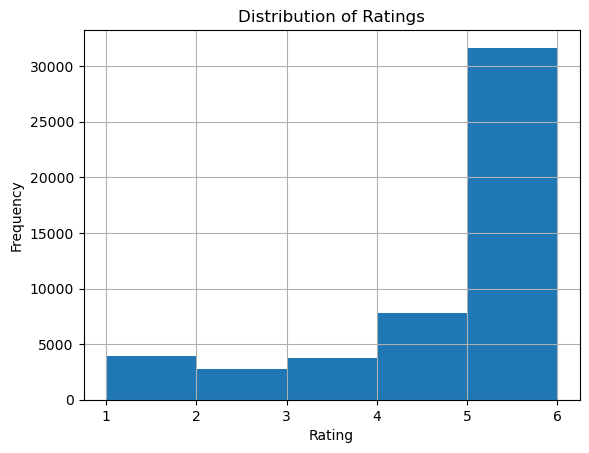

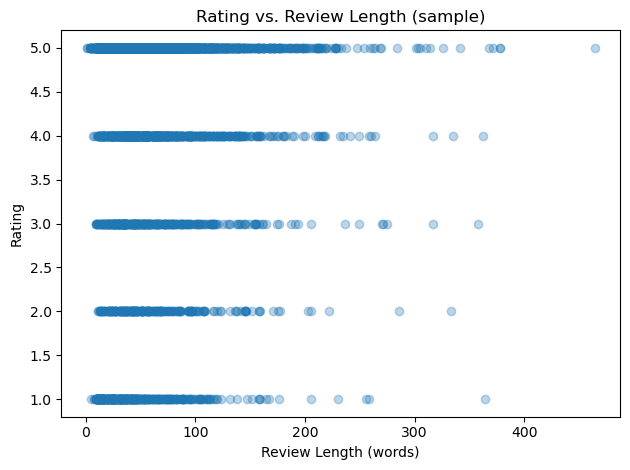

In [61]:
# ==========================================================
# 7️⃣ Visualization – Matplotlib Only (No Custom Colors)
# ==========================================================

# --- Ratings Histogram
if col_rating and col_rating in saphora.columns:
    plt.figure()
    saphora[col_rating].hist(bins=[1, 2, 3, 4, 5, 6])
    plt.xlabel("Rating")
    plt.ylabel("Frequency")
    plt.title("Distribution of Ratings")
    plt.show()

# --- Price Histogram (clipped at 99th percentile)
if col_price and col_price in saphora.columns:
    plt.figure()
    saphora[col_price].clip(upper=saphora[col_price].quantile(0.99)).hist(bins=30)
    plt.xlabel("Price (clipped at 99th percentile)")
    plt.ylabel("Frequency")
    plt.title("Distribution of Prices")
    plt.show()

# --- Average Rating by Top 10 Brands
if col_rating and col_brand and col_rating in saphora.columns and col_brand in saphora.columns:
    top10 = (
        saphora.groupby(col_brand)[col_rating]
        .agg(["count", "mean"])
        .sort_values("count", ascending=False)
        .head(10)
        .reset_index()
    )
    plt.figure()
    plt.bar(top10[col_brand].astype(str), top10["mean"])
    plt.xlabel("Brand (Top 10 by Count)")
    plt.ylabel("Average Rating")
    plt.title("Average Rating by Brand (Top 10)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# --- Rating vs Review Length (scatter sample)
if col_rating and "review_len" in saphora.columns:
    plt.figure()
    sample = saphora.sample(min(5000, len(saphora)), random_state=42)
    plt.scatter(sample["review_len"], sample[col_rating], alpha=0.3)
    plt.xlabel("Review Length (words)")
    plt.ylabel("Rating")
    plt.title("Rating vs. Review Length (sample)")
    plt.tight_layout()
    plt.show()

,25%,50%,75%
unnamed:_0,12465.750000,25042.500000,37509.25
rating,4.000000,5.000000,5.00
is_recommended,1.000000,1.000000,1.00
helpfulness,0.666667,0.887473,1.00
total_feedback_count,0.000000,3.000000,8.00
total_neg_feedback_count,0.000000,0.000000,1.00
total_pos_feedback_count,0.000000,2.000000,6.00
price_usd,27.000000,45.000000,74.00
review_len,33.000000,49.000000,76.00


✅ Quartile summary saved as sephora_uncleaned_quartiles.csv


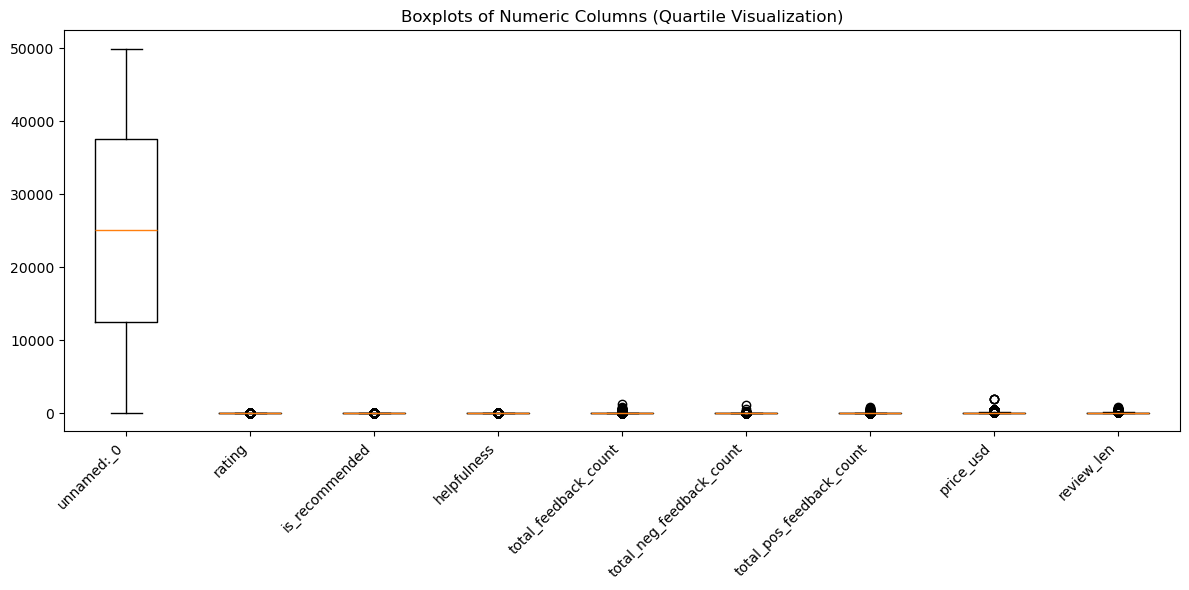

✅ Boxplot saved as sephora_uncleaned_quartiles_boxplots.png


In [59]:
num_df = saphora.select_dtypes(include=['number'])
if num_df.empty:
    print('⚠️ No numeric columns found.')
else:
    quartiles = num_df.describe(percentiles=[0.25, 0.5, 0.75]).T[['25%', '50%', '75%']]
    display(quartiles)
    quartiles.to_csv('sephora_uncleaned_quartiles.csv')
    print('✅ Quartile summary saved as sephora_uncleaned_quartiles.csv')

    # Boxplot visualization
    plt.figure(figsize=(12,6))
    plt.boxplot([num_df[c].dropna().values for c in num_df.columns], tick_labels=num_df.columns)
    plt.title('Boxplots of Numeric Columns (Quartile Visualization)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('sephora_uncleaned_quartiles_boxplots.png', dpi=300)
    plt.show()
    print('✅ Boxplot saved as sephora_uncleaned_quartiles_boxplots.png')

In [65]:
# ==========================================================
# 8️⃣ Correlations & Reporting Notes
# ==========================================================

corrs = {}

# --- Correlation between rating and helpfulness
if col_helpful and col_rating and col_helpful in saphora.columns and col_rating in saphora.columns:
    saphora[col_helpful] = pd.to_numeric(saphora[col_helpful], errors="coerce")
    corrs["rating_helpful_corr"] = float(saphora[[col_rating, col_helpful]].corr().iloc[0, 1])

# --- Correlation between rating and review length
if col_rating and "review_len" in saphora.columns:
    corrs["rating_reviewlen_corr"] = float(saphora[[col_rating, "review_len"]].corr().iloc[0, 1])

# --- Display correlation results
print("📈 Correlations:")
for key, val in corrs.items():
    print(f" {key}: {val:.4f}")



📈 Correlations:
 rating_helpful_corr: 0.1758
 rating_reviewlen_corr: 0.0352


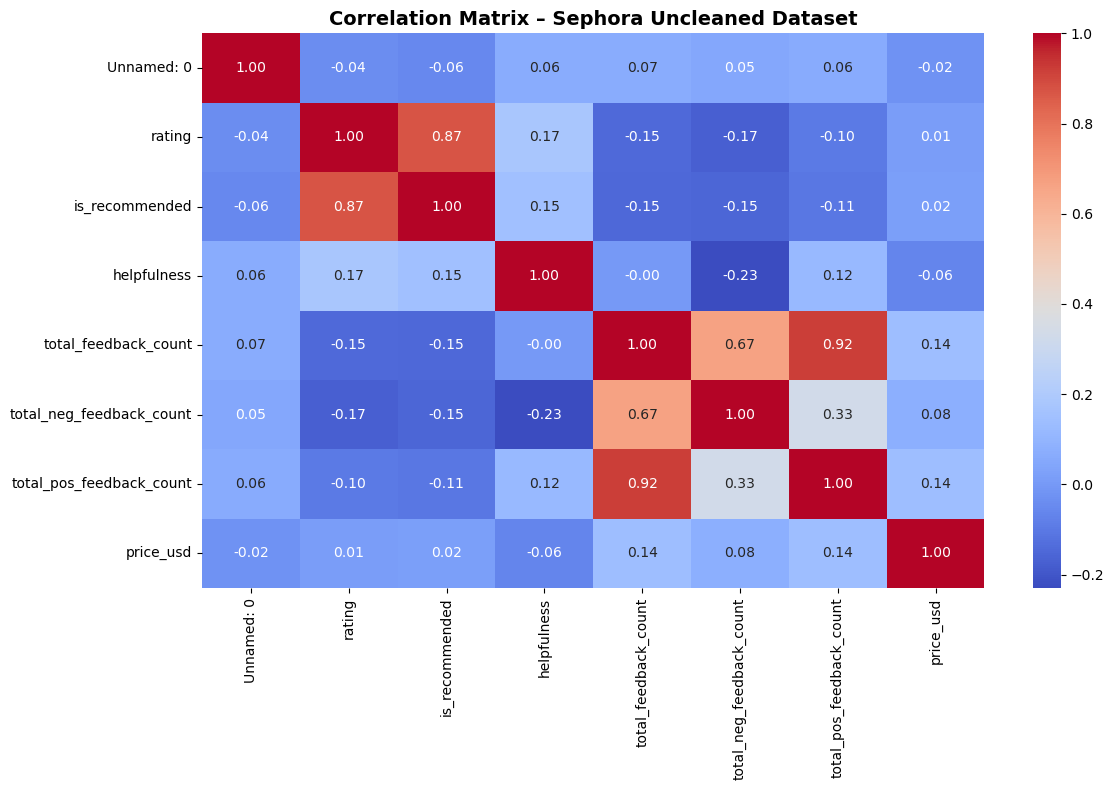

✅ Correlation heatmap saved as sephora_uncleaned_correlation_heatmap.png


In [45]:
drop_cols = [c for c in ['quality', 'wine_type'] if c in saphora.columns]
numeric_df = saphora.select_dtypes(include=['number'])

if numeric_df.shape[1] < 2:
    print('⚠️ Not enough numeric columns to compute correlation matrix.')
else:
    correlation_matrix = numeric_df.drop(columns=drop_cols, errors='ignore').corr()
    plt.figure(figsize=(12,8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Matrix – Sephora Uncleaned Dataset', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12,8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Matrix – Sephora Uncleaned Dataset', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('sephora_uncleaned_correlation_heatmap.png', dpi=300)
    plt.close()
    print('✅ Correlation heatmap saved as sephora_uncleaned_correlation_heatmap.png')

✅ Scaled numeric columns using MinMaxScaler:
['unnamed:_0', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'price_usd', 'review_len']


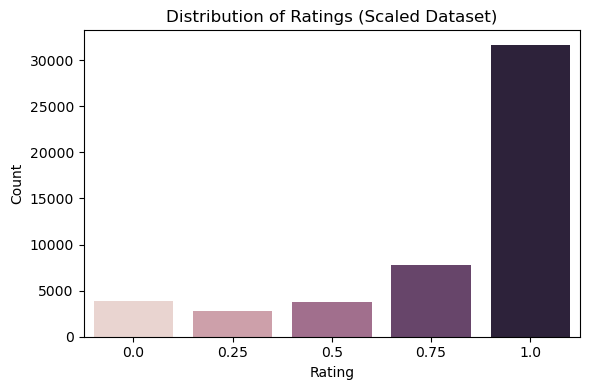

In [71]:
# ==========================================================
# 9️⃣ Scale Numeric Columns – Sephora Dataset
# ==========================================================

from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt

cols_to_drop = [col for col in ['quality', 'quality_label'] if col in saphora.columns]
numeric_cols = saphora.select_dtypes(include=['float64', 'int64']).drop(columns=cols_to_drop, errors='ignore').columns

if len(numeric_cols) > 0:
    scaler = MinMaxScaler()
    saphora[numeric_cols] = scaler.fit_transform(saphora[numeric_cols])
    print("✅ Scaled numeric columns using MinMaxScaler:")
    print(list(numeric_cols))
else:
    print("⚠️ No numeric columns found to scale.")

if col_rating and col_rating in saphora.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col_rating, hue=col_rating, data=saphora, legend=False)
    plt.title("Distribution of Ratings (Scaled Dataset)")
    plt.xlabel("Rating")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()